In [ ]:
import time

time.sleep(60*60*4)  


In [ ]:
import json
import pandas as pd
import shutil
from pathlib import Path

data = []

file = "data/Semantic40-T.json"
with open(file, "r") as f:
    # While not end of file
    for l in f:      # If end of file, break
        #Convert to JSON
        d = json.loads(l)
        data.append(d) 
        
df = pd.DataFrame(data)

In [ ]:
import mteb
import numpy as np

leaderboard = pd.read_csv("model_selection/MTEB_leaderboard.csv", index_col=0)

model_metas = mteb.get_model_metas()
full_model_names = [m.name for m in model_metas]


leaderboard["Model_Short"] = leaderboard["Model"].str.extract(r"\[([^\]]+)\]")

model_names = []
for name in leaderboard["Model_Short"]:
    n = ""
    for full_name in full_model_names:
        if str(name) in full_name:
            n = full_name
            model_names.append(full_name)
            break
    if n == "":
        model_names.append(name)

leaderboard["Model"] = model_names
leaderboard.to_csv("text.csv")


238


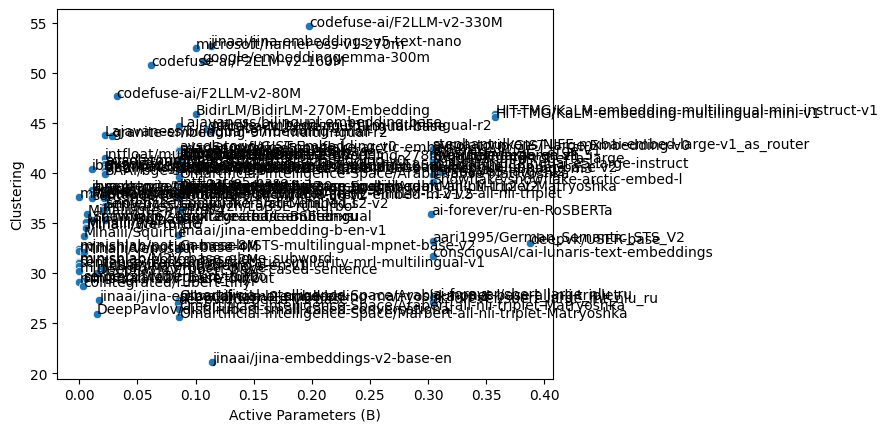

In [30]:
import seaborn as sns
import numpy as np

leaderboard = leaderboard.sort_values(by="Clustering", ascending=False)

lb_df = leaderboard[leaderboard["Active Parameters (B)"]<1.5].reset_index(drop = True)

is_efficient = np.ones(lb_df.shape[0], dtype=bool)

for i, c in lb_df.iterrows():
    if is_efficient[i]:
        is_efficient[i] = not np.any(
            (c["Clustering"]<=lb_df["Clustering"]) & 
            (c["Active Parameters (B)"]>=lb_df["Active Parameters (B)"]) & 
            (c["Model"] != lb_df["Model"]) & 
            (c["Model"] != "sentence-transformers/all-MiniLM-L6-v2") & 
            (c["Model"] != "sentence-transformers/all-mpnet-base-v2")
        )


ax = sns.scatterplot(lb_df, x = "Active Parameters (B)", y = "Clustering")

for _, m in lb_df.iterrows():
    ax.text(x=m["Active Parameters (B)"], y = m["Clustering"], s = m["Model"])

print(len(lb_df))

In [31]:
lb_df

,Rank (Borda),Model,Zero-shot,Active Parameters (B),Total Parameters (B),Embedding Dimensions,Max Tokens,Mean (Task),Mean (TaskType),Bitext Mining,Classification,Clustering,Instruction Reranking,Multilabel Classification,Pair Classification,Reranking,Retrieval,STS,Model_Short
0,4,codefuse-ai/F2LLM-v2-330M,88%,0.198,0.334,896.0,40960.0,60.84,53.27,69.80,61.69,54.69,-1.65,24.56,77.79,63.35,56.50,72.73,F2LLM-v2-330M
1,3,jinaai/jina-embeddings-v5-text-nano,⚠️ NA,0.113,0.212,768.0,8192.0,65.52,57.66,67.70,69.18,52.73,0.05,41.31,81.94,64.63,63.26,78.17,jina-embeddings-v5-text-nano
2,1,microsoft/harrier-oss-v1-270m,78%,0.100,0.268,640.0,32768.0,66.55,56.90,81.54,70.84,52.51,-0.47,23.97,80.12,61.90,66.38,75.35,harrier-oss-v1-270m
3,2,google/embeddinggemma-300m,99%,0.106,0.308,768.0,2048.0,61.15,54.31,64.40,60.90,51.17,5.61,24.82,81.40,63.25,62.49,74.73,embeddinggemma-300m
4,9,codefuse-ai/F2LLM-v2-160M,88%,0.062,0.159,640.0,40960.0,57.98,50.61,65.59,58.86,50.83,-3.39,23.05,76.02,60.34,54.08,70.10,F2LLM-v2-160M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233,250,lightonai/LateOn-Code-pretrain,100%,0.110,0.149,128.0,8192.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,LateOn-Code-pretrain
234,251,bisectgroup/BiCA-base,100%,0.086,0.109,768.0,512.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BiCA-base
235,252,lightonai/LateOn-Code-edge-pretrain,100%,0.004,0.017,48.0,7999.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,LateOn-Code-edge-pretrain
236,253,fyaronskiy/english_code_retriever,100%,0.110,0.149,768.0,8192.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,english_code_retriever


In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.metrics import v_measure_score, homogeneity_score, completeness_score
from sklearn.metrics import adjusted_mutual_info_score
import time

def k_means(embeddings, n_clusters = 40):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    start_time = time.time()
    kmeans.fit(embeddings)
    labels = kmeans.labels_
    end_time = time.time()
    
    elapsed_time = end_time - start_time
    nmi = normalized_mutual_info_score(df["topic"].tolist(), labels)
    ami = adjusted_mutual_info_score(df["topic"].tolist(), labels)
    v_measure = v_measure_score(df["topic"].tolist(), labels)
    homogeneity = homogeneity_score(df["topic"].tolist(), labels)
    completeness = completeness_score(df["topic"].tolist(), labels)

    result = {
        "elapsed_time_k_means" : elapsed_time,
        "nmi" : nmi,
        "ami" : ami,
        "v_measure" : v_measure,
        "homogeneity" : homogeneity,
        "completeness" : completeness
    }

    return result

In [ ]:
import time
import json
import os
import shutil
from sentence_transformers import SentenceTransformer
from huggingface_hub import scan_cache_dir

RESULTS_FILE = "model_selection_results.jsonl"

models = list(lb_df["Model"].values)
models += ["sentence-transformers/all-MiniLM-L12-v1"]
models += ["sentence-transformers/all-MiniLM-L6-v1"]

# --- Resume logic: figure out which models are already done ---
completed_models = set()
if os.path.exists(RESULTS_FILE):
    with open(RESULTS_FILE, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                entry = json.loads(line)
                completed_models.add(entry["model_name"])
            except json.JSONDecodeError:
                # last line may be truncated if the process was killed mid-write
                print(f"Skipping corrupted line: {line[:80]}...")

print(f"Found {len(completed_models)} already-completed models, skipping those.")

# Open in append mode so existing entries are preserved
with open(RESULTS_FILE, "a") as f:
    for model_name in models:
        if model_name in completed_models:
            print("Already done, skipping: " + model_name)
            continue

        try:
            print("Testing: " + model_name)
            transformer = SentenceTransformer(model_name, device="cpu")
            start_time = time.time()
            embeddings = transformer.encode(df["tweets"].tolist(), show_progress_bar=True)
            end_time = time.time()

            elapsed_time = end_time - start_time
            result = k_means(embeddings, n_clusters=40)
            result["model_name"] = model_name
            result["elapsed_time_embeddings"] = elapsed_time
            result["elapsed_time_sum"] = result["elapsed_time_embeddings"] + result["elapsed_time_k_means"]

            # Write immediately and flush to disk
            f.write(json.dumps(result) + "\n")
            f.flush()
            os.fsync(f.fileno())

            completed_models.add(model_name)

            del transformer
            # 🔥 remove cached model files
            cache_dir = scan_cache_dir()
            for repo in cache_dir.repos:
                if model_name.split("/")[-1] in repo.repo_id:
                    shutil.rmtree(repo.repo_path)

        except Exception as ex:
            print("Failed: " + model_name)
            print(ex)

# --- Load everything back into a DataFrame/list when needed ---
results = []
with open(RESULTS_FILE, "r") as f:
    for line in f:
        line = line.strip()
        if line:
            results.append(json.loads(line))

Found 204 already-completed models, skipping those.
Already done, skipping: codefuse-ai/F2LLM-v2-330M
Testing: jinaai/jina-embeddings-v5-text-nano
Failed: jinaai/jina-embeddings-v5-text-nano
No module named 'custom_st'
Already done, skipping: microsoft/harrier-oss-v1-270m
Testing: google/embeddinggemma-300m
Failed: google/embeddinggemma-300m
You are trying to access a gated repo.
Make sure to have access to it at https://huggingface.co/google/embeddinggemma-300m.
401 Client Error. (Request ID: Root=1-6a67967b-059425dd6ae102d736bfb1fa;a0ea379b-f737-4ce2-88d4-03c695b5edc2)

Cannot access gated repo for url https://huggingface.co/google/embeddinggemma-300m/resolve/main/config.json.
Access to model google/embeddinggemma-300m is restricted. You must have access to it and be authenticated to access it. Please log in.
Already done, skipping: codefuse-ai/F2LLM-v2-160M
Already done, skipping: codefuse-ai/F2LLM-v2-80M
Testing: BidirLM/BidirLM-270M-Embedding
Failed: BidirLM/BidirLM-270M-Embedding

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4620.76it/s]


Failed: avsolatorio/NoInstruct-small-Embedding-v0
Pooling.__init__() got an unexpected keyword argument 'output_key'
Already done, skipping: intfloat/multilingual-e5-large-instruct
Already done, skipping: avsolatorio/GIST-small-Embedding-v0
Already done, skipping: ibm-granite/granite-embedding-107m-multilingual
Already done, skipping: ibm-granite/granite-embedding-125m-english
Already done, skipping: thenlper/gte-small-zh
Already done, skipping: abhinand/MedEmbed-small-v0.1
Already done, skipping: sentence-transformers/all-mpnet-base-v2
Already done, skipping: sentence-transformers/paraphrase-multilingual-mpnet-base-v2
Already done, skipping: sdadas/mmlw-roberta-base
Already done, skipping: intfloat/e5-base-v2
Already done, skipping: deepvk/USER-bge-m3
Already done, skipping: BAAI/bge-small-en-v1.5
Already done, skipping: intfloat/e5-large-v2
Already done, skipping: Omartificial-Intelligence-Space/Arabic-labse-Matryoshka
Already done, skipping: Snowflake/snowflake-arctic-embed-l
Alread

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 21444.04it/s]
XLMRobertaModel LOAD REPORT from: KennethEnevoldsen/dfm-sentence-encoder-medium
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Failed: KennethEnevoldsen/dfm-sentence-encoder-medium
Unrecognized processing class in KennethEnevoldsen/dfm-sentence-encoder-medium. Can't instantiate a processor, a tokenizer, an image processor, a video processor or a feature extractor for this model. Make sure the repository contains the files of at least one of those processing classes.
Already done, skipping: panalexeu/xlm-roberta-ua-distilled
Already done, skipping: rasgaard/m2v-dfm-large
Already done, skipping: andersborges/model2vecdk-stem
Already done, skipping: andersborges/model2vecdk
Already done, skipping: keeeeenw/MicroLlama-text-embedding
Already done, skipping: BAAI/bge-large-zh-v1.5
Already done, skipping: BAAI/bge-base-zh-v1.5
Already done, skipping: dunzhang/stella-large-zh-v3-1792d
Already done, skipping: infgrad/stella-base-zh-v3-1792d
Already done, skipping: OrdalieTech/Solon-embeddings-mini-beta-1.1
Already done, skipping: DMetaSoul/Dmeta-embedding-zh-small
Already done, skipping: KFST/XLMRoberta-en-da-sv-nb
Alr

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 16215.52it/s]


... (9 outputs left out)

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 4609.50it/s]


Failed: OpenSearch-AI/Ops-MoA-Yuan-embedding-1.0
No module named 'modeling_adaptor'
Testing: OpenSearch-AI/Ops-MoA-Conan-embedding-v1


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 26380.12it/s]


Failed: OpenSearch-AI/Ops-MoA-Conan-embedding-v1
No module named 'modeling_adaptor'
Already done, skipping: fangxq/XYZ-embedding
Testing: codefuse-ai/C2LLM-0.5B
Failed: codefuse-ai/C2LLM-0.5B
No module named 'custom_transformer'
Already done, skipping: lightonai/LateOn-Code-edge
Already done, skipping: lightonai/LateOn-Code-pretrain
Already done, skipping: bisectgroup/BiCA-base
Already done, skipping: lightonai/LateOn-Code-edge-pretrain
Already done, skipping: fyaronskiy/english_code_retriever
Already done, skipping: colbert-ir/colbertv2.0
Already done, skipping: sentence-transformers/all-MiniLM-L12-v1
Already done, skipping: sentence-transformers/all-MiniLM-L6-v1


In [7]:
df = pd.DataFrame(results)

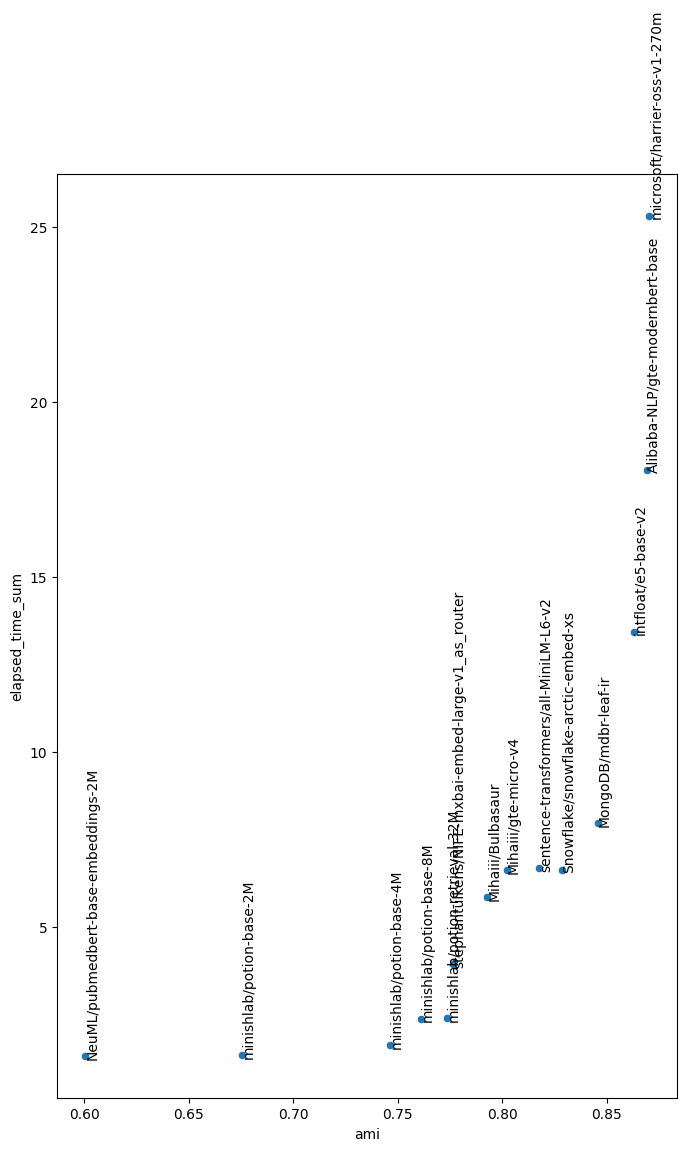

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 12)) 

is_efficient = np.ones(df.shape[0], dtype=bool)

#models += [ "sentence-transformers/paraphrase-MiniLM-L6-v2"]
#models += [ "sentence-transformers/all-MiniLM-L6-v2"]

for i, c in df.iterrows():
    if is_efficient[i]:
        is_efficient[i] = not np.any(
            ((c["ami"] + 0.000)<=df["ami"]) & 
            (c["elapsed_time_sum"] - 0.0>=df["elapsed_time_sum"]) & 
            (c["model_name"] != df["model_name"]) & 
            (c["model_name"] != "sentence-transformers/paraphrase-MiniLM-L3-v2") &
            (c["model_name"] != "sentence-transformers/all-MiniLM-L6-v2") )

df_optimal = df[is_efficient]

ax = sns.scatterplot(df_optimal, x = "ami", y = "elapsed_time_sum")

for _, row in df_optimal.iterrows():
    ax.text(x=row["ami"], y=row["elapsed_time_sum"], s=row["model_name"], rotation=90)





In [27]:
df_optimal.sort_values(by="ami")["model_name"][6]

'stephantulkens/NIFE-mxbai-embed-large-v1_as_router'